Setup and load

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)

df = pd.read_csv("../data/raw/cs-training.csv", index_col=0)
print(df.shape)
df.info()

(150000, 11)
<class 'pandas.DataFrame'>
RangeIndex: 150000 entries, 1 to 150000
Data columns (total 11 columns):
 #   Column                                Non-Null Count   Dtype  
---  ------                                --------------   -----  
 0   SeriousDlqin2yrs                      150000 non-null  int64  
 1   RevolvingUtilizationOfUnsecuredLines  150000 non-null  float64
 2   age                                   150000 non-null  int64  
 3   NumberOfTime30-59DaysPastDueNotWorse  150000 non-null  int64  
 4   DebtRatio                             150000 non-null  float64
 5   MonthlyIncome                         120269 non-null  float64
 6   NumberOfOpenCreditLinesAndLoans       150000 non-null  int64  
 7   NumberOfTimes90DaysLate               150000 non-null  int64  
 8   NumberRealEstateLoansOrLines          150000 non-null  int64  
 9   NumberOfTime60-89DaysPastDueNotWorse  150000 non-null  int64  
 10  NumberOfDependents                    146076 non-null  float64
dty

Class balance

SeriousDlqin2yrs
0    139974
1     10026
Name: count, dtype: int64
SeriousDlqin2yrs
0    93.32
1     6.68
Name: count, dtype: float64


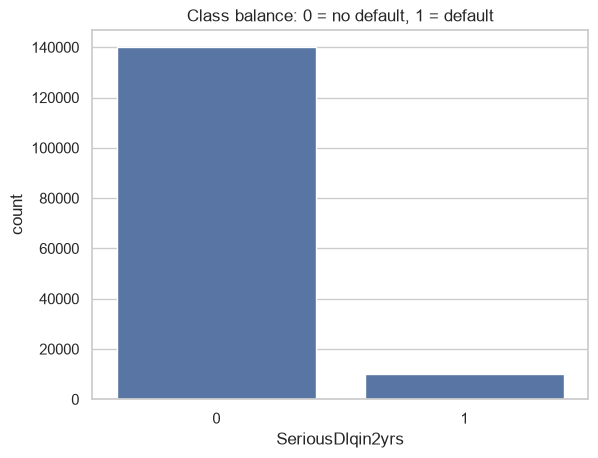

In [2]:
counts = df["SeriousDlqin2yrs"].value_counts()
print(counts)
print((counts / len(df) * 100).round(2))

sns.countplot(x="SeriousDlqin2yrs", data=df)
plt.title("Class balance: 0 = no default, 1 = default")
plt.show()

Missing values

In [3]:
missing = df.isna().sum()
pd.DataFrame({"missing": missing, "percent": (missing / len(df) * 100).round(2)})

,missing,percent
SeriousDlqin2yrs,0,0.00
RevolvingUtilizationOfUnsecuredLines,0,0.00
age,0,0.00
NumberOfTime30-59DaysPastDueNotWorse,0,0.00
DebtRatio,0,0.00
MonthlyIncome,29731,19.82
NumberOfOpenCreditLinesAndLoans,0,0.00
NumberOfTimes90DaysLate,0,0.00
NumberRealEstateLoansOrLines,0,0.00
NumberOfTime60-89DaysPastDueNotWorse,0,0.00


Summary statistics and outliers

In [4]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
SeriousDlqin2yrs,150000.0,0.066840,0.249746,0.0,0.000000,0.000000,0.000000,1.0
RevolvingUtilizationOfUnsecuredLines,150000.0,6.048438,249.755371,0.0,0.029867,0.154181,0.559046,50708.0
age,150000.0,52.295207,14.771866,0.0,41.000000,52.000000,63.000000,109.0
NumberOfTime30-59DaysPastDueNotWorse,150000.0,0.421033,4.192781,0.0,0.000000,0.000000,0.000000,98.0
DebtRatio,150000.0,353.005076,2037.818523,0.0,0.175074,0.366508,0.868254,329664.0
MonthlyIncome,120269.0,6670.221237,14384.674215,0.0,3400.000000,5400.000000,8249.000000,3008750.0
NumberOfOpenCreditLinesAndLoans,150000.0,8.452760,5.145951,0.0,5.000000,8.000000,11.000000,58.0
NumberOfTimes90DaysLate,150000.0,0.265973,4.169304,0.0,0.000000,0.000000,0.000000,98.0
NumberRealEstateLoansOrLines,150000.0,1.018240,1.129771,0.0,0.000000,1.000000,2.000000,54.0
NumberOfTime60-89DaysPastDueNotWorse,150000.0,0.240387,4.155179,0.0,0.000000,0.000000,0.000000,98.0


Outlier details

In [5]:
print("Age == 0:", (df["age"] == 0).sum())
print("Age > 100:", (df["age"] > 100).sum())
print("Utilization > 1:", (df["RevolvingUtilizationOfUnsecuredLines"] > 1).sum())
print("DebtRatio > 10:", (df["DebtRatio"] > 10).sum())
print("Late counts == 96 or 98:", df["NumberOfTimes90DaysLate"].isin([96, 98]).sum())

Age == 0: 1
Age > 100: 13
Utilization > 1: 3321
DebtRatio > 10: 28877
Late counts == 96 or 98: 269


Default rate vs age

In [6]:
df["age_group"] = pd.cut(df["age"], bins=[0, 25, 35, 45, 55, 65, 120])
print(df.groupby("age_group", observed=True)["SeriousDlqin2yrs"].mean().round(3))
df = df.drop(columns="age_group")

age_group
(0, 25]      0.112
(25, 35]     0.111
(35, 45]     0.088
(45, 55]     0.076
(55, 65]     0.046
(65, 120]    0.024
Name: SeriousDlqin2yrs, dtype: float64


Correlation heatmap

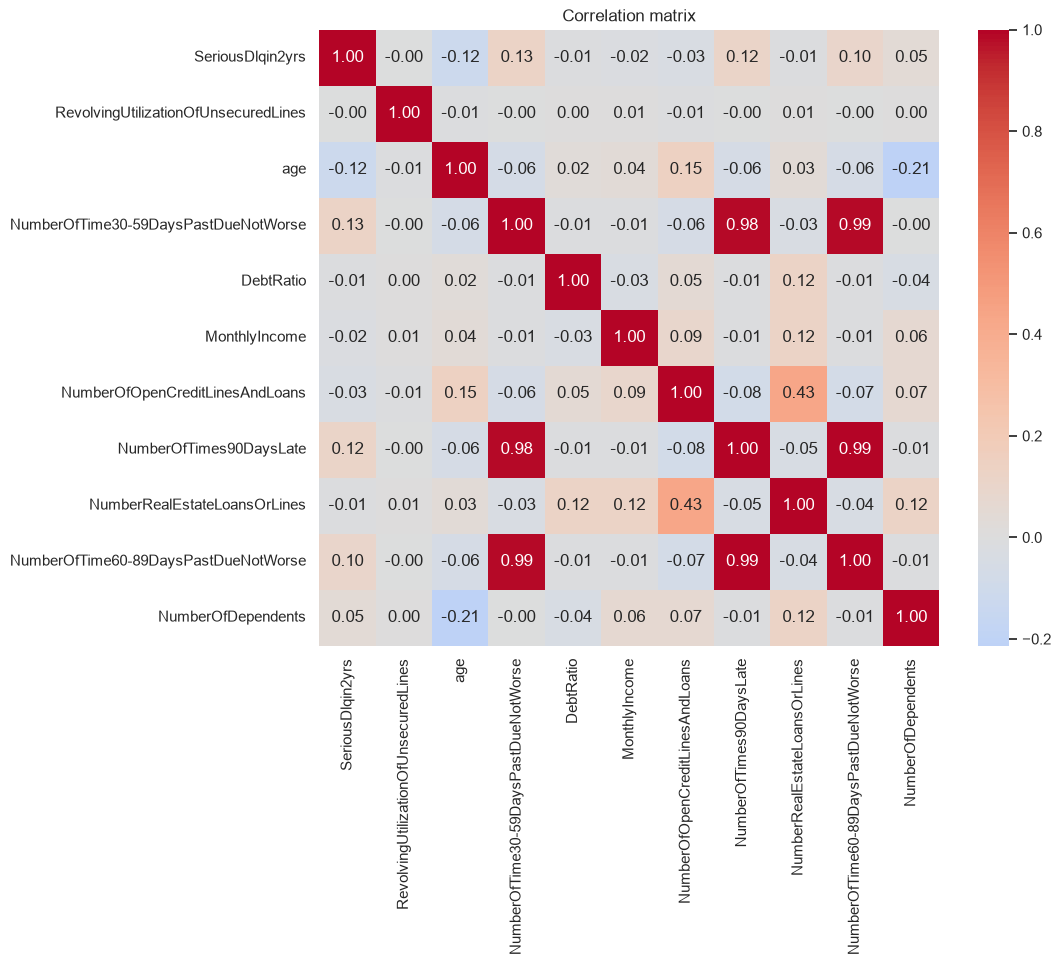

In [7]:
plt.figure(figsize=(10, 8))
sns.heatmap(df.corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation matrix")
plt.show()

In [8]:
print("DebtRatio > 10 with income missing:",
      ((df["DebtRatio"] > 10) & df["MonthlyIncome"].isna()).sum())
print("DebtRatio > 10 with income present:",
      ((df["DebtRatio"] > 10) & df["MonthlyIncome"].notna()).sum())

DebtRatio > 10 with income missing: 26771
DebtRatio > 10 with income present: 2106


**Finding:** 93% of rows with DebtRatio > 10 (26,771 of 28,877) have missing MonthlyIncome.
This suggests DebtRatio holds a raw debt amount rather than a ratio when income is unknown.
I'll treat DebtRatio as missing in those rows and add a missing-income indicator in the pipeline.